In [79]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rjmanoj/credit-card-customer-churn-prediction/Churn_Modelling.csv


In [80]:
df = pd.read_csv('/kaggle/input/datasets/rjmanoj/credit-card-customer-churn-prediction/Churn_Modelling.csv')

In [81]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [82]:
df.shape

(10000, 14)

In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [84]:
df.duplicated().sum()

np.int64(0)

In [85]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [86]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [87]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [88]:
df.drop(columns=['RowNumber',"Surname","CustomerId"],inplace=True)

In [89]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [90]:
df =pd.get_dummies(df, columns=['Geography','Gender'],drop_first=True)

In [91]:
X=df.drop(columns=['Exited'])
y=df['Exited']

In [92]:
X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,True,False,True


In [93]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [94]:
X_train.shape

(8000, 11)

In [95]:
from sklearn.preprocessing import StandardScaler

In [96]:
scaler = StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [97]:
X_train_scaled

array([[ 0.35649971, -0.6557859 ,  0.34567966, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [-0.20389777,  0.29493847, -0.3483691 , ...,  1.72572313,
        -0.57638802,  0.91324755],
       [-0.96147213, -1.41636539, -0.69539349, ..., -0.57946723,
         1.73494238,  0.91324755],
       ...,
       [ 0.86500853, -0.08535128, -1.38944225, ..., -0.57946723,
        -0.57638802, -1.09499335],
       [ 0.15932282,  0.3900109 ,  1.03972843, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [ 0.47065475,  1.15059039, -1.38944225, ...,  1.72572313,
        -0.57638802,  0.91324755]])

In [98]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [99]:
model = Sequential()


# model.add(Dense(3,activation='sigmoid',input_dim = 11))
# model.add(Dense(1,activation='sigmoid'))


model.add(Dense(11,activation='relu',input_dim = 11))
model.add(Dense(11,activation='relu'))
model.add(Dense(1,activation='sigmoid'))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [100]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [101]:
model.compile(loss='binary_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [102]:
history = model.fit(X_train_scaled,y_train,epochs=100,validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7294 - loss: 0.5735 - val_accuracy: 0.8031 - val_loss: 0.4825
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8055 - loss: 0.4538 - val_accuracy: 0.8181 - val_loss: 0.4307
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8186 - loss: 0.4234 - val_accuracy: 0.8250 - val_loss: 0.4151
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8242 - loss: 0.4081 - val_accuracy: 0.8300 - val_loss: 0.4007
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8364 - loss: 0.3927 - val_accuracy: 0.8388 - val_loss: 0.3855
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8452 - loss: 0.3775 - val_accuracy: 0.8469 - val_loss: 0.3725
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8517 - loss: 0.3655 - val_accuracy: 0.8444 - val_loss: 0.3644
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8542 - loss: 0.3580 - val_accu

In [103]:
model.layers[0].get_weights()

[array([[ 0.10847808, -0.18636906, -0.21798404, -0.06422065, -0.03378168,
         -0.08889017,  0.13946229, -0.01772596,  0.39187658, -0.03426868,
          0.02683679],
        [ 0.7772075 ,  0.105544  ,  0.6213042 , -0.7607835 ,  0.08822966,
         -0.13999449,  0.87465864,  0.26800135, -0.4534985 , -0.52724844,
         -0.8675583 ],
        [-0.05256577,  0.12538078,  0.09266751,  0.00627589, -0.04738708,
         -0.5517038 , -0.05124954,  0.04204211, -0.07382232,  0.06453361,
         -0.09042041],
        [ 0.21858992,  0.1865177 ,  0.29602435, -0.10262079, -0.2502595 ,
          0.48661482, -0.6116536 ,  0.00275343, -0.5017988 , -0.3469509 ,
          0.03673261],
        [ 0.3716557 , -0.8883086 ,  0.29965413, -0.03224493, -1.065516  ,
          0.00602836, -0.02046098,  1.0814599 , -0.55583096, -0.18637533,
         -0.48515475],
        [-0.2349454 , -0.25501686, -0.00142576, -0.05603335, -0.15386266,
         -0.46072748, -0.52595574, -0.24445324, -0.23984969, -0.0598653

In [104]:
model.layers[1].get_weights()


[array([[ 0.06304729,  0.2507635 ,  0.2979373 , -1.4328473 ,  0.17348568,
         -0.16701753,  0.4714441 , -0.3174043 ,  0.21952458, -0.31386942,
          0.45803195],
        [ 0.12953183, -1.3752853 ,  0.05633861, -0.45175594,  0.33862025,
          0.28857598, -0.35141176,  0.2918063 ,  0.10377429, -0.7646516 ,
         -0.5850167 ],
        [ 0.809018  ,  0.6022242 , -0.6292446 , -0.0222349 ,  0.15359457,
         -0.11031067, -0.00604483, -0.47091118,  0.5182057 ,  0.21162556,
          0.34191388],
        [-0.0252698 , -0.3530171 , -0.03829896,  0.45787853, -1.1044856 ,
         -0.34300792,  0.59375364,  0.16129269,  0.15817119, -0.6462352 ,
          0.53790814],
        [ 0.16700302, -0.65994453,  0.46512225, -0.78147405,  0.8111685 ,
          0.7087629 , -0.6556426 , -0.7138605 , -0.68377024, -1.5935212 ,
         -0.6543214 ],
        [ 0.18145937,  0.477245  , -0.03512035,  0.22990255,  0.51879704,
         -0.12056979,  0.2365584 ,  0.3929138 ,  0.21173623, -0.2041369

In [105]:
model.layers[2].get_weights()

[array([[-0.5331561 ],
        [ 1.5299413 ],
        [ 1.0857855 ],
        [ 1.095056  ],
        [ 0.68917996],
        [ 0.78701293],
        [-0.73270494],
        [-0.75645137],
        [-0.5092424 ],
        [-0.9135553 ],
        [-0.99512213]], dtype=float32),
 array([-0.12070292], dtype=float32)]

In [106]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [107]:
y_pred = np.where(y_log>0.5,1,0)

In [108]:
y_pred

array([[0],
       [0],
       [0],
       ...,
       [1],
       [0],
       [0]])

In [109]:
from sklearn.metrics import accuracy_score 
accuracy_score(y_test,y_pred)

0.86

In [110]:
import matplotlib.pyplot as plt

In [111]:
# history.history

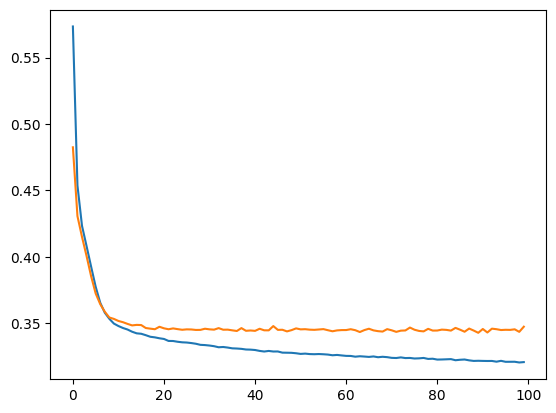

In [112]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])



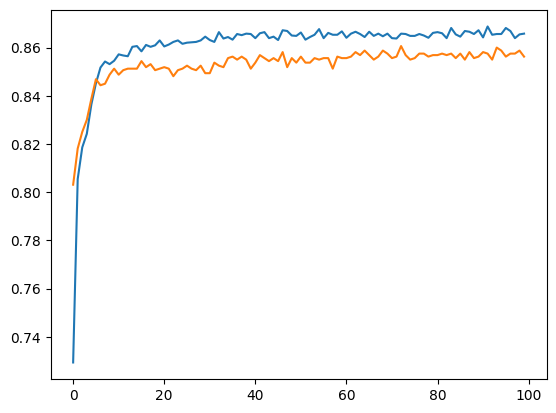

In [113]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
